# 04 A/B test analysis: the effect of the SMS

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** Before deciding *whom* to contact, we measure *whether* the SMS works at all: its average effect on the purchase rate, how precisely the experiment measures it, and whether it differs between client groups. Causal claims are made only here, inside the randomized experiment.

**Summary.** The SMS raised the share of clients who made a purchase from 60.3% to 63.7%, about 33 extra buyers per 1,000 messages, and checks on the control group show that this measurement can be trusted. The effect is far from equal: about 5 points among clients who are unlikely to buy anyway, and only 1 point among those who almost always buy. Sending the SMS to the most likely buyers, a common default, would spend the budget where it adds least.

**Research question.** How much does the SMS raise the purchase rate, overall and across client groups?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

from x5uplift import plotting as P
from x5uplift.config import PROPENSITY_PATH, SEED, SEGMENTS_PATH
from x5uplift.experiment import Z, cuped, diff_in_means, heterogeneity_test, relative_lift, subgroup_effects
from x5uplift.modeling import load_experiment

pd.set_option("display.width", 140)
P.set_style()

## 1. Data

All 200,039 experiment clients, with their segment (notebook 02) and their predicted probability of buying without an SMS (notebook 03). The probability uses only information from before the SMS, so its mean should be the same in both groups.

In [2]:
exp = (
    load_experiment()
    .merge(pd.read_parquet(SEGMENTS_PATH)[["client_id", "segment_name"]], on="client_id", validate="one_to_one")
    .merge(pd.read_parquet(PROPENSITY_PATH), on="client_id", validate="one_to_one")
)
t = exp["treatment_flg"].to_numpy()
y = exp["target"].to_numpy()

exp.groupby("treatment_flg").agg(
    clients=("target", "size"),
    purchase_rate=("target", "mean"),
    mean_p_buy_without_sms=("p_buy_without_sms", "mean"),
).round(4)

,clients,purchase_rate,mean_p_buy_without_sms
treatment_flg,,,
0,100058,0.6033,0.6033
1,99981,0.6365,0.6042


The predicted probability is 60.33% in the control group and 60.42% in the SMS group, a difference of about one standard error, so it is balanced and can be used for adjustment.

## 2. Average effect

The SMS group's purchase rate minus the control group's. Because clients were assigned at random, this difference is the causal effect of the SMS. It is given in percentage points and relative to the control rate, so it is not confused with "sales uplift" figures that measure something else.

In [3]:
ate, lift = diff_in_means(y, t), relative_lift(y, t)
print(f"Purchase rate: control {y[t == 0].mean():.2%}, SMS {y[t == 1].mean():.2%}")
print(f"Effect: {100 * ate['effect']:.2f} points [{100 * ate['ci_low']:.2f}, {100 * ate['ci_high']:.2f}], p = {ate['p_value']:.1e}")
print(f"Relative to control: {lift['lift']:+.1%} [{lift['ci_low']:+.1%}, {lift['ci_high']:+.1%}]")
print(f"Extra purchasing clients per 1,000 SMS: {1000 * ate['effect']:.0f}")

Purchase rate: control 60.33%, SMS 63.65%
Effect: 3.32 points [2.90, 3.75], p = 5.8e-53
Relative to control: +5.5% [+4.8%, +6.2%]
Extra purchasing clients per 1,000 SMS: 33


The SMS raises the purchase rate by 3.3 points (95% interval 2.9 to 3.8), or 5.5% relative to the control rate: about 33 extra purchasing clients per 1,000 messages.

## 3. Measuring the effect more precisely

Past behaviour explains much of who buys (notebook 03). Removing that predictable part from the outcome should narrow the interval without moving the estimate. Three adjustments are compared with the plain difference:

* **CUPED** subtracts the part of the outcome explained by one pre-experiment metric, the number of visits in the last 30 days.
* **CUPAC** does the same with the predicted purchase probability from notebook 03, which combines all features.
* **Regression adjustment** regresses the outcome on the SMS flag, six pre-experiment metrics and their interactions (Lin's estimator), with robust standard errors.

All three use only information from before the SMS, so they cannot create an effect, only remove noise. A variance reduction of *r* gives the same precision as a plain comparison with 1 / (1 − *r*) times as many clients.

In [4]:
# Regression adjustment: centred covariates, so the sms coefficient is the average effect (Lin, 2013)
reg_cols = ["n_baskets_recent", "n_baskets_previous", "days_since_last_purchase",
            "log_total_spend", "redeemed_before_cutoff", "days_since_card_issue"]
d = exp.assign(log_total_spend=np.log1p(exp["total_spend"]))[reg_cols]
assert d.notna().all().all()
d = (d - d.mean()).assign(target=y, sms=t)
reg = smf.ols(f"target ~ sms * ({' + '.join(reg_cols)})", data=d).fit(cov_type="HC1")
lo, hi = reg.conf_int().loc["sms"]

methods = pd.DataFrame({
    "Difference in means": ate,
    "CUPED (visits, last 30 days)": cuped(y, t, exp["n_baskets_recent"]),
    "CUPAC (predicted probability)": cuped(y, t, exp["p_buy_without_sms"]),
    "Regression adjustment": {"effect": reg.params["sms"], "se": reg.bse["sms"], "ci_low": lo, "ci_high": hi},
}).T[["effect", "se", "ci_low", "ci_high"]].astype(float)

methods["variance_reduction_pct"] = 100 * (1 - (methods["se"] / methods["se"].iloc[0]) ** 2)
(methods[["effect", "se", "ci_low", "ci_high"]] * 100).round(2).join(methods["variance_reduction_pct"].round(1))

,effect,se,ci_low,ci_high,variance_reduction_pct
Difference in means,3.32,0.22,2.90,3.75,0.0
"CUPED (visits, last 30 days)",3.25,0.20,2.86,3.65,12.4
CUPAC (predicted probability),3.24,0.19,2.86,3.62,22.0
Regression adjustment,3.21,0.20,2.83,3.60,17.6


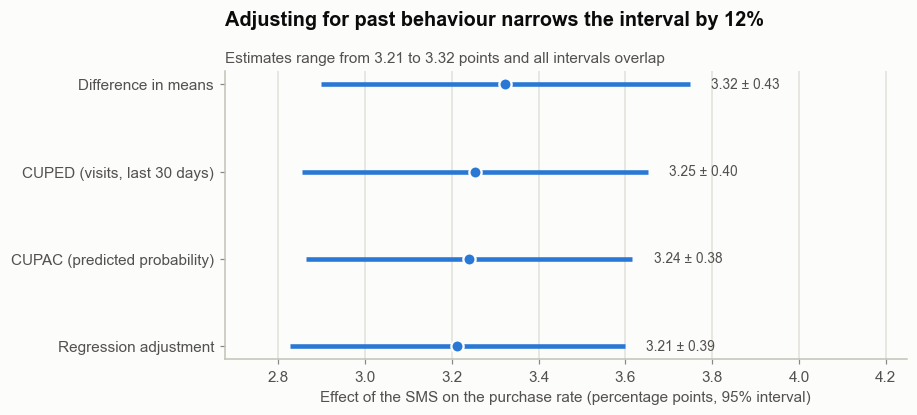

In [5]:
m = (methods * 100).iloc[::-1]                      # first method at the top
narrower = 1 - m["se"].min() / m["se"].iloc[-1]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(m["effect"], m.index, xerr=Z * m["se"], fmt="o", color=P.BLUE, markersize=8,
            markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=3)
for name, r in m.iterrows():
    ax.text(r["effect"] + Z * r["se"] + 0.05, name, f"{r['effect']:.2f} ± {Z * r['se']:.2f}",
            va="center", fontsize=9, color=P.INK_2)
ax.set(xlim=(m["ci_low"].min() - 0.15, m["ci_high"].max() + 0.5),
       xlabel="Effect of the SMS on the purchase rate (percentage points, 95% interval)")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
P.titles(ax, f"Adjusting for past behaviour narrows the interval by {narrower:.0%}",
         f"Estimates range from {m['effect'].min():.2f} to {m['effect'].max():.2f} points and all intervals overlap")
P.save(fig, "04_variance_reduction")

All three adjustments agree with the plain difference. CUPAC removes the most noise: a 22% variance reduction, worth about 28% more clients, and a 12% narrower interval. The adjusted estimates are 0.07 to 0.11 points lower because the SMS group had, by chance, a slightly higher predicted purchase probability (60.42% against 60.33%); the adjustment removes this chance advantage, and the shift is well inside the interval. The plain difference stays the headline estimate, as planned. CUPAC is used below where precision matters.

## 4. A/A tests

A test is only useful if it rarely finds effects that are not there. Splitting the *control* group (nobody received an SMS) into two random halves creates comparisons with no real difference. If the test is correct, about 5% of such splits give p < 0.05 and the p-values are spread evenly between 0 and 1. With 1,000 splits, a correct rate falls between about 3.6% and 6.4%.

In [6]:
rng = np.random.default_rng(SEED)
y0 = y[t == 0]
p0 = exp.loc[t == 0, "p_buy_without_sms"].to_numpy()
half = np.arange(len(y0)) < len(y0) // 2

aa = []
for _ in range(1000):
    fake = rng.permutation(half)
    aa.append({"Difference in means": diff_in_means(y0, fake)["p_value"],
               "CUPAC": cuped(y0, fake, p0)["p_value"]})
aa = pd.DataFrame(aa)

pd.DataFrame({
    "false_positive_rate_pct": 100 * (aa < 0.05).mean(),
    "ks_test_uniform_p": aa.apply(lambda s: stats.kstest(s, "uniform").pvalue),
}).round(3)

,false_positive_rate_pct,ks_test_uniform_p
Difference in means,4.4,0.569
CUPAC,4.1,0.746


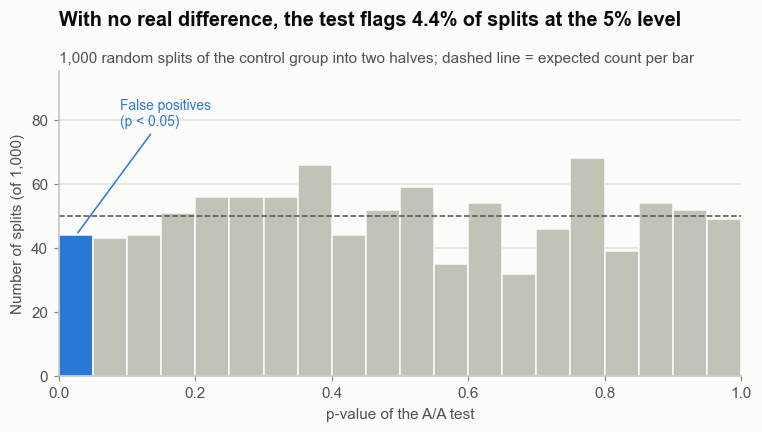

In [7]:
fpr = (aa["Difference in means"] < 0.05).mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
counts, edges, bars = ax.hist(aa["Difference in means"], bins=np.linspace(0, 1, 21),
                              color=P.AXIS, edgecolor=P.SURFACE, linewidth=1)
bars[0].set_facecolor(P.BLUE)  # p < 0.05: a false positive
ax.axhline(len(aa) / 20, color=P.INK_2, linewidth=1, linestyle="--")
ax.annotate("False positives\n(p < 0.05)", xy=(0.025, counts[0]), xytext=(0.09, counts.max() * 1.15),
            fontsize=9, color=P.BLUE, arrowprops=dict(arrowstyle="-", color=P.BLUE, linewidth=1))
ax.set(xlim=(0, 1), ylim=(0, counts.max() * 1.4),
       xlabel="p-value of the A/A test", ylabel=f"Number of splits (of {len(aa):,})")
P.titles(ax, f"With no real difference, the test flags {fpr:.1%} of splits at the 5% level",
         "1,000 random splits of the control group into two halves; dashed line = expected count per bar")
P.save(fig, "04_aa_tests")

In 1,000 splits of the control group, the test gives p < 0.05 in 4.4% of cases (CUPAC 4.1%), inside the 3.6% to 6.4% expected for a correct test, and the p-values are spread evenly (KS test p = 0.57 and 0.75). The test does not find effects that are not there.

## 5. Power: which effects can this experiment detect?

**Semi-synthetic test.** The control group is split into two random halves and a known effect is injected into one half: a random share of its non-buyers is turned into buyers, so that the purchase rate rises by exactly the chosen number of points. This creates experiments where the true effect is known. For each effect size, 300 runs show how often the test finds it (power), whether the estimate is centred on the truth (bias) and how often the 95% interval contains it (coverage). The injected effect is the same for every client, which is a simplification: it tests the method, not how real clients respond.

In [8]:
rng = np.random.default_rng(SEED)
rows = []
for delta in [0, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015]:
    for _ in range(300):
        fake = rng.permutation(half)
        q = delta / (1 - y0[fake].mean())                    # share of non-buyers turned into buyers
        y_sim = y0.copy()
        y_sim[fake & (y0 == 0) & (rng.random(len(y0)) < q)] = 1
        true = y_sim[fake].mean() - y0[fake].mean()          # effect actually injected in this run
        for method, res in [("Difference in means", diff_in_means(y_sim, fake)), ("CUPAC", cuped(y_sim, fake, p0))]:
            rows.append({"method": method, "injected_points": 100 * delta, "error": res["effect"] - true,
                         "detected": res["p_value"] < 0.05, "covered": res["ci_low"] <= true <= res["ci_high"]})
sim = pd.DataFrame(rows)

(sim.groupby(["injected_points", "method"])
    .agg(power=("detected", "mean"), coverage=("covered", "mean"), bias_points=("error", lambda e: 100 * e.mean()))
    .unstack("method").round(3))

power                     coverage                     bias_points                    
method           CUPAC Difference in means    CUPAC Difference in means       CUPAC Difference in means
injected_points                                                                                        
0.00             0.057               0.060    0.943               0.940       0.023               0.031
0.25             0.137               0.113    0.960               0.960       0.017               0.026
0.50             0.503               0.430    0.960               0.947       0.025               0.028
0.75             0.803               0.687    0.957               0.960      -0.004               0.003
1.00             0.977               0.920    0.943               0.963       0.019               0.025
1.25             0.997               0.983    0.950               0.953       0.013               0.013
1.50             1.000               0.997    0.943               0.940       0.008              -0.007

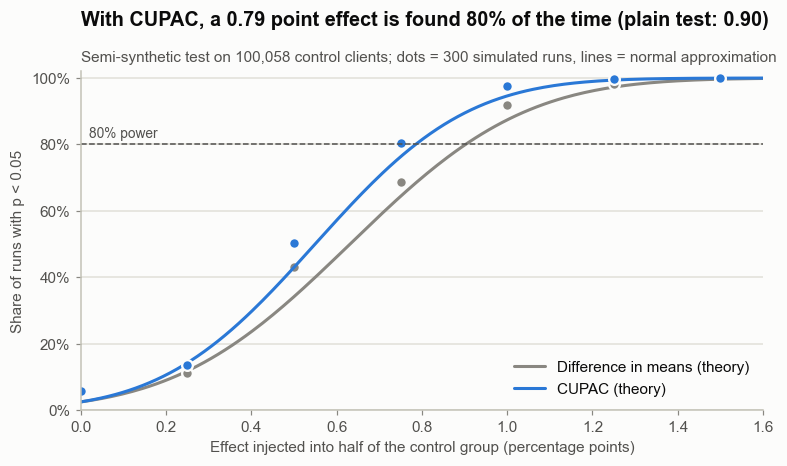

In [9]:
z = Z + stats.norm.ppf(0.80)
se_sim = 100 * sim[sim["injected_points"] == 0].groupby("method")["error"].std()   # spread of estimates, in points
mde = z * se_sim

fig, ax = plt.subplots(figsize=(8, 4))
grid = np.linspace(0, 1.6, 200)
for method, color in [("Difference in means", P.MUTED), ("CUPAC", P.BLUE)]:
    ax.plot(grid, stats.norm.cdf(grid / se_sim[method] - Z), color=color, label=f"{method} (theory)")
    s = sim[sim["method"] == method].groupby("injected_points")["detected"].mean()
    ax.plot(s.index, s.values, "o", color=color, markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5)
ax.axhline(0.8, color=P.INK_2, linewidth=1, linestyle="--")
ax.text(0.02, 0.82, "80% power", fontsize=9, color=P.INK_2)
ax.set(xlim=(0, 1.6), ylim=(0, 1.02), xlabel="Effect injected into half of the control group (percentage points)",
       ylabel="Share of runs with p < 0.05")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(loc="lower right")
P.titles(ax, f"With CUPAC, a {mde['CUPAC']:.2f} point effect is found 80% of the time (plain test: {mde['Difference in means']:.2f})",
         "Semi-synthetic test on 100,058 control clients; dots = 300 simulated runs, lines = normal approximation")
P.save(fig, "04_power")

In [10]:
# Smallest effect found 80% of the time inside a group of n experiment clients (about half with an SMS).
# Approximation: scales the full experiment standard error by sqrt(N / n), so it assumes similar purchase rates.
se_all = pd.Series({"Difference in means": ate["se"], "CUPAC": methods.loc["CUPAC (predicted probability)", "se"]})
n_test = int(exp["is_test"].sum())
groups = {
    "All experiment clients": len(exp),
    "Test set": n_test,
    "One propensity decile": len(exp) // 10,
    "Test set, top 20% (budget)": n_test // 5,
    "Test set, top 10% (budget)": n_test // 10,
    "Smallest segment (Express point collectors)": int(exp["segment_name"].value_counts().min()),
}
mde_table = pd.DataFrame({g: 100 * z * se_all * np.sqrt(len(exp) / n) for g, n in groups.items()}).T.round(2)
mde_table.insert(0, "clients", pd.Series(groups))
mde_table

,clients,Difference in means,CUPAC
All experiment clients,200039,0.61,0.54
Test set,60012,1.11,0.98
One propensity decile,20003,1.92,1.70
"Test set, top 20% (budget)",12002,2.48,2.19
"Test set, top 10% (budget)",6001,3.51,3.10
Smallest segment (Express point collectors),2333,5.63,4.97


At every injected size the estimates are centred on the truth (bias within ±0.03 points, about the Monte Carlo error of 0.02) and the 95% intervals contain it 94% to 96% of the time. In half of the control group, CUPAC finds a 0.79 point effect 80% of the time; the plain test needs 0.90.

Scaled to the real experiment, the smallest effect found 80% of the time (CUPAC) is 0.54 points overall, 1.7 points inside one decile of purchase probability, 2.2 points in a 20% budget group of the test set, 3.1 points in a 10% budget group and 5.0 points in the smallest segment. The observed 3.3 point effect is far above the first number, but differences between small groups have to be large to be seen one by one.

## 6. Does the effect differ between clients?

Subgroups are defined only by information from before the SMS, so each subgroup comparison is still a randomized experiment. Four variables are examined: segment (notebook 02), age band, gender and decile of the predicted probability of buying without an SMS (notebook 03). The last one matters most for targeting: do clients who would buy anyway respond less?

With 26 subgroups, some would look different by chance. Two corrections are reported: Holm (controls the chance of any false finding) and Benjamini and Hochberg (controls the expected share of false findings). For each variable, Cochran's Q test asks whether its group effects differ more than chance allows. Because single deciles are too small to compare one by one (section 5), one planned trend test uses all clients at once: a regression with an SMS × purchase probability interaction. All effects here are CUPAC estimates.

In [11]:
exp["age_band"] = (pd.cut(exp["age"], [13, 29, 39, 49, 59, 100],
                          labels=["14 to 29", "30 to 39", "40 to 49", "50 to 59", "60 and over"])
                     .cat.add_categories("missing").fillna("missing"))
exp["p_decile"] = pd.qcut(exp["p_buy_without_sms"], 10, labels=range(1, 11))

by = {"Segment": "segment_name", "Age": "age_band", "Gender": "gender", "Purchase probability decile": "p_decile"}
sub = pd.concat({name: subgroup_effects(exp, col, x="p_buy_without_sms") for name, col in by.items()},
                names=["variable", "group"])
sub["p_holm"] = multipletests(sub["p_value"], method="holm")[1]
sub["p_bh"] = multipletests(sub["p_value"], method="fdr_bh")[1]

show = sub[["clients", "control_rate", "effect", "ci_low", "ci_high"]].copy()
show.iloc[:, 1:] *= 100                                   # rates and effects in points
show.round(2).join(sub[["p_value", "p_holm", "p_bh"]].apply(lambda s: s.map("{:.1e}".format)))

clients  control_rate  effect  ci_low  ci_high  p_value   p_holm     p_bh
variable                    group                                                                                                  
Segment                     Alcohol and own brand buyers    13183         53.98    3.17    1.63     4.70  5.2e-05  3.7e-04  6.8e-05
                            Big basket shoppers             45465         63.95    2.15    1.32     2.98  3.8e-07  3.8e-06  5.7e-07
                            Daily top-up shoppers           48687         86.93    1.52    0.96     2.08  9.0e-08  9.9e-07  1.5e-07
                            Express point collectors         2333         66.49    4.12    0.54     7.70  2.4e-02  4.8e-02  2.5e-02
                            Occasional shoppers             32452         30.31    3.73    2.74     4.72  1.6e-13  3.0e-12  5.1e-13
                            Point redeemers                 10377         33.98    7.98    6.18     9.77  2.9e-18  6.4e-17  1.5e-17
                            Regular small baskets           47542         57.67    4.63    3.78     5.47  1.0e-26  2.4e-25  8.7e-26
Age                         14 to 29                        31576         57.92    1.80    0.84     2.76  2.4e-04  1.2e-03  2.8e-04
                            30 to 39                        44682         59.28    2.41    1.61     3.21  3.5e-09  5.0e-08  7.1e-09
                            40 to 49                        38468         59.45    2.82    1.96     3.68  1.3e-10  2.0e-09  3.0e-10
                            50 to 59                        35610         60.51    3.72    2.82     4.61  4.0e-16  8.0e-15  1.5e-15
                            60 and over                     48820         63.57    4.91    4.17     5.65  1.7e-38  4.3e-37  4.3e-37
                            missing                           883         51.85    4.13   -1.77    10.03  1.7e-01  1.7e-01  1.7e-01
Gender                      F                               73696         62.04    3.88    3.26     4.49  2.0e-35  5.1e-34  2.6e-34
                            M                               33511         60.68    3.18    2.26     4.10  1.2e-11  2.0e-10  3.0e-11
                            U                               92832         58.84    2.75    2.20     3.31  2.9e-22  6.6e-21  1.9e-21
Purchase probability decile 1                               20004         21.40    5.03    3.85     6.20  4.8e-17  1.0e-15  2.1e-16
                            2                               20004         32.56    3.72    2.41     5.04  2.8e-08  3.4e-07  4.9e-08
                            3                               20004         40.95    4.98    3.61     6.35  1.1e-12  2.0e-11  3.1e-12
                            4                               20004         49.45    4.37    2.98     5.75  6.1e-10  9.1e-09  1.3e-09
                            5                               20004         56.79    4.03    2.67     5.39  6.7e-09  8.7e-08  1.2e-08
                            6                               20003         65.33    2.36    1.05     3.67  4.0e-04  1.6e-03  4.5e-04
                            7                               20004         73.27    2.60    1.39     3.80  2.3e-05  1.9e-04  3.2e-05
                            8                               20004         80.60    2.54    1.47     3.60  3.1e-06  2.8e-05  4.5e-06
                            9                               20004         88.03    1.74    0.87     2.61  8.7e-05  5.2e-04  1.1e-04
                            10                              20004         95.44    0.98    0.43     1.52  4.5e-04  1.6e-03  4.9e-04

In [12]:
het = (sub.groupby(level="variable", sort=False)
          .apply(lambda d: heterogeneity_test(d["effect"], d["se"]))
          .to_frame("p_heterogeneity"))
het["p_holm"] = multipletests(het["p_heterogeneity"], method="holm")[1]

# Planned trend test: sms:p10 is the change in effect per 10 points of purchase probability
d = pd.DataFrame({"target": y, "sms": t,
                  "p10": 10 * (exp["p_buy_without_sms"] - exp["p_buy_without_sms"].mean())})
trend = smf.ols("target ~ sms * p10", data=d).fit(cov_type="HC1")
slope, (s_lo, s_hi) = 100 * trend.params["sms:p10"], 100 * trend.conf_int().loc["sms:p10"]
print(f"Change in effect per 10 points of purchase probability: {slope:+.2f} points "
      f"[{s_lo:+.2f}, {s_hi:+.2f}], p = {trend.pvalues['sms:p10']:.1e}")
het.round(4)

Change in effect per 10 points of purchase probability: -0.53 points [-0.67, -0.38], p = 8.4e-13


,p_heterogeneity,p_holm
variable,,
Segment,0.0000,0.0000
Age,0.0000,0.0000
Gender,0.0284,0.0284
Purchase probability decile,0.0000,0.0000


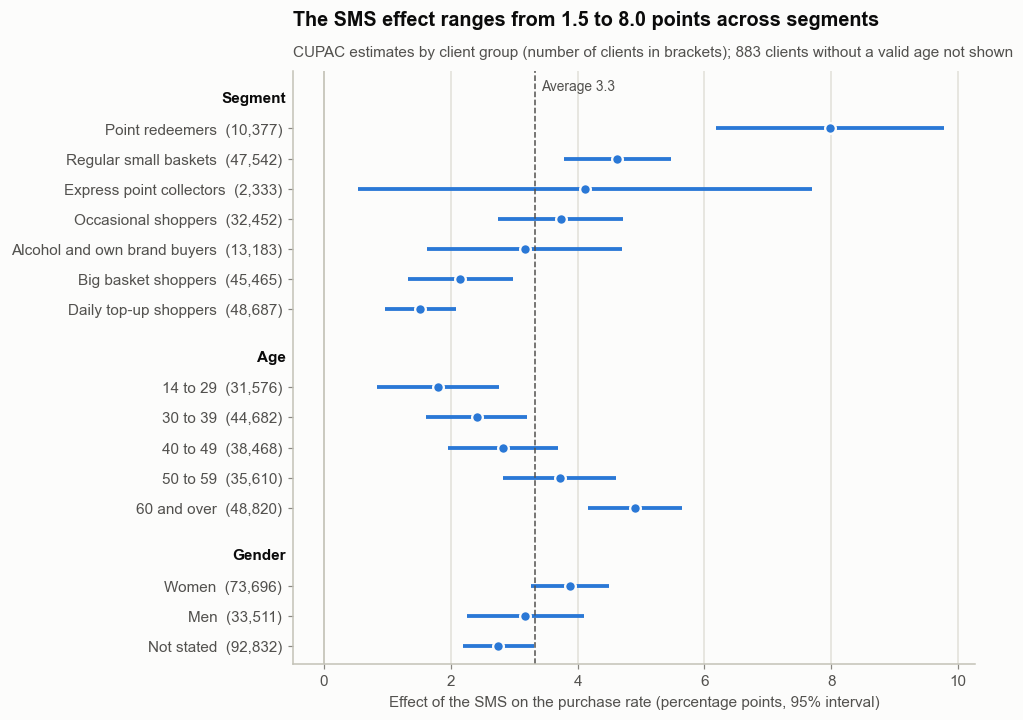

In [13]:
names = {"F": "Women", "M": "Men", "U": "Not stated"}
blocks = {"Segment": sub.loc["Segment"].sort_values("effect", ascending=False),
          "Age": sub.loc["Age"].drop("missing"), "Gender": sub.loc["Gender"]}

fig, ax = plt.subplots(figsize=(8, 7))
top, ticks, labels = 0, [], []
for var, b in blocks.items():
    ax.text(-0.01, top, var, transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold")
    rows = top - 1 - np.arange(len(b))
    ax.errorbar(100 * b["effect"], rows, xerr=100 * Z * b["se"], fmt="o", color=P.BLUE, markersize=7,
                markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2.5)
    ticks += list(rows)
    labels += [f"{names.get(g, g)}  ({n:,})" for g, n in zip(b.index, b["clients"])]
    top = rows[-1] - 1.6
ax.axvline(100 * ate["effect"], color=P.INK_2, linewidth=1, linestyle="--")
ax.text(100 * ate["effect"] + 0.1, 0.4, f"Average {100 * ate['effect']:.1f}", fontsize=9, color=P.INK_2, va="center")
ax.axvline(0, color=P.AXIS, linewidth=1)
ax.set_yticks(ticks, labels)
ax.set(ylim=(top + 1, 0.9), xlabel="Effect of the SMS on the purchase rate (percentage points, 95% interval)")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
seg = blocks["Segment"]["effect"]
P.titles(ax, f"The SMS effect ranges from {100 * seg.min():.1f} to {100 * seg.max():.1f} points across segments",
         "CUPAC estimates by client group (number of clients in brackets); 883 clients without a valid age not shown")
P.save(fig, "04_subgroups")

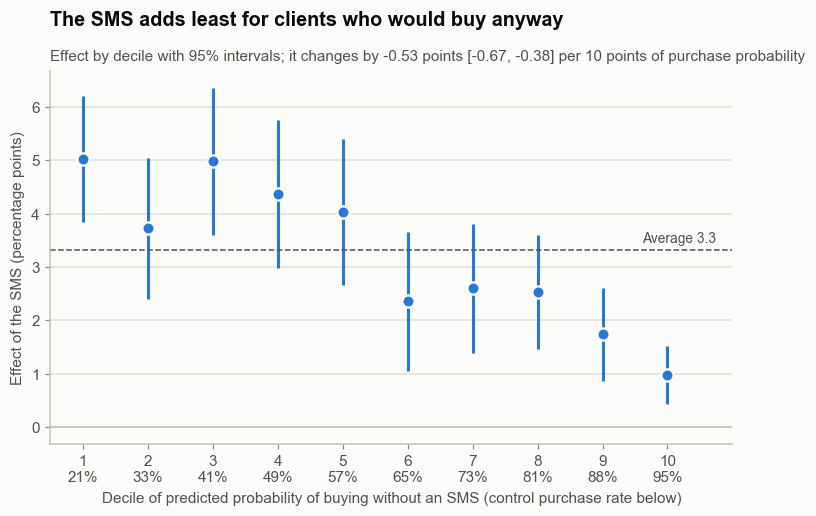

In [14]:
dec = sub.loc["Purchase probability decile"]
x = np.arange(1, 11)

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.errorbar(x, 100 * dec["effect"], yerr=100 * Z * dec["se"], fmt="o", color=P.BLUE, markersize=8,
            markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2)
ax.axhline(100 * ate["effect"], color=P.INK_2, linewidth=1, linestyle="--")
ax.text(10.75, 100 * ate["effect"] + 0.08, f"Average {100 * ate['effect']:.1f}", fontsize=9, color=P.INK_2, ha="right", va="bottom")
ax.axhline(0, color=P.AXIS, linewidth=1)
ax.set_xticks(x, [f"{d}\n{r:.0%}" for d, r in zip(x, dec["control_rate"])])
ax.set(xlim=(0.5, 11), ylabel="Effect of the SMS (percentage points)",
       xlabel="Decile of predicted probability of buying without an SMS (control purchase rate below)")
P.titles(ax, "The SMS adds least for clients who would buy anyway",
         f"Effect by decile with 95% intervals; it changes by {slope:+.2f} points [{s_lo:+.2f}, {s_hi:+.2f}] per 10 points of purchase probability")
P.save(fig, "04_effect_by_propensity")

The effect differs between clients more than chance allows for segment, age and purchase probability (Cochran's Q, Holm adjusted p < 0.001) and weakly for gender (p = 0.028). It is positive in all 26 groups and significant after Holm correction in 25 of them; the exception is the 883 clients without a valid age.

* **Purchase probability.** The effect falls by 0.53 points [0.38, 0.67] per 10 points of purchase probability (p = 8e-13): about 4 to 5 points in the lower half and 1.0 point in the top decile, where 95% of clients buy anyway. Part of this is a ceiling: in the top decile only 4.6% of clients are left to convert. For a budget decision the absolute effect is what counts, so contacting likely buyers spends the SMS where it adds least. There is no sign of "lost causes" at the bottom: the clients least likely to buy respond most, as expected in a sample of recently active clients.
* **Segments.** Point redeemers respond most, 8.0 points [6.2, 9.8]. Their purchase rate (34%) is close to that of occasional shoppers (30%, effect 3.7 points), so the difference is not only a ceiling. Daily top-up shoppers respond least, 1.5 points. Why point redeemers respond more is unknown: the content of the SMS is not in the data.
* **Age.** The effect rises from 1.8 points (14 to 29) to 4.9 points (60 and over), while the purchase rate rises only from 58% to 64%. Age carries information about the response that purchase probability does not.

These groups overlap (daily top-up shoppers sit mostly in the top deciles), so the findings are not independent. They describe for whom the SMS works; they do not show that age or point use causes a stronger response.

## Conclusion

**Answer.** The SMS raises the purchase rate by 3.3 points (95% interval 2.9 to 3.8), 5.5% relative to the control rate, or about 33 extra purchasing clients per 1,000 messages. The effect is not the same for everyone: it falls from about 5 points among clients least likely to buy anyway to 1 point among those most likely to buy.

**What we learned**
* The test is reliable: A/A splits give 4.4% false positives at the 5% level, and injected effects are recovered without bias and with 95% coverage.
* CUPAC removes 22% of the variance, worth about 28% more clients. It is used wherever precision matters.
* Precision limits what targeting results can claim: inside a 10% budget group of the test set, only effects of about 3 points or more are detected reliably.
* The effect varies by segment, age and purchase probability, so there is something for an uplift model to learn.

**What remains open**
* The outcome is a yes or no purchase within a time window that is not documented. The data cannot tell whether the SMS creates new purchases or only moves planned ones earlier, or whether it changes how much clients spend. Notebook 06 therefore treats the value of an extra purchase as an assumption, not a measurement.
* The content of the SMS is unknown, so the reasons behind the differences, such as the strong response of point redeemers, cannot be explained.
* All clients made their last purchase within 22 days of the campaign. The results describe recently active clients, not lapsed ones.
* Subgroup results use all 200,039 clients, including the test set kept for notebook 06. To keep that evaluation honest, every modelling choice in notebook 05 is made by cross validation on the training folds only.

**Next step.** Notebook 05 builds uplift models that predict the effect for each client from all features together, instead of one variable at a time, and checks on held out data whether their ranking separates strong and weak responders.